In [5]:
import pandas as pd 
import numpy as np

In [6]:

import pandas as pd

# Load Heart Disease Dataset
df = pd.read_csv(
    r"C:\Users\lenovo\Downloads\archive (15)\heart.csv"
)

# Display first 5 rows
print("Dataset Loaded Successfully!")
display(df.head())

# Check dataset dimensions
print("Dataset Shape:", df.shape)


Dataset Loaded Successfully!


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,52,1,0,125,212,0,1,168,0,1.0,2,2,3,0
1,53,1,0,140,203,1,0,155,1,3.1,0,0,3,0
2,70,1,0,145,174,0,1,125,1,2.6,0,0,3,0
3,61,1,0,148,203,0,1,161,0,0.0,2,1,3,0
4,62,0,0,138,294,1,1,106,0,1.9,1,3,2,0


Dataset Shape: (1025, 14)


In [7]:

# STEP 2: DATA EXPLORATION

print("===== DATASET INFORMATION =====")
df.info()

print("\n===== DATASET DIMENSIONS =====")
print("Rows and Columns:", df.shape)

print("\n===== COLUMN NAMES =====")
print(df.columns.tolist())

print("\n===== MISSING VALUES =====")
print(df.isnull().sum())

print("\n===== DUPLICATE ROWS =====")
print(df.duplicated().sum())

print("\n===== TARGET DISTRIBUTION =====")
print(df['target'].value_counts())

print("\n===== STATISTICAL SUMMARY =====")
display(df.describe())


===== DATASET INFORMATION =====
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1025 entries, 0 to 1024
Data columns (total 14 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       1025 non-null   int64  
 1   sex       1025 non-null   int64  
 2   cp        1025 non-null   int64  
 3   trestbps  1025 non-null   int64  
 4   chol      1025 non-null   int64  
 5   fbs       1025 non-null   int64  
 6   restecg   1025 non-null   int64  
 7   thalach   1025 non-null   int64  
 8   exang     1025 non-null   int64  
 9   oldpeak   1025 non-null   float64
 10  slope     1025 non-null   int64  
 11  ca        1025 non-null   int64  
 12  thal      1025 non-null   int64  
 13  target    1025 non-null   int64  
dtypes: float64(1), int64(13)
memory usage: 112.2 KB

===== DATASET DIMENSIONS =====
Rows and Columns: (1025, 14)

===== COLUMN NAMES =====
['age', 'sex', 'cp', 'trestbps', 'chol', 'fbs', 'restecg', 'thalach', 'exang', 'oldpeak', 'slope'

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
count,1025.000000,1025.000000,1025.000000,1025.000000,1025.00000,1025.000000,1025.000000,1025.000000,1025.000000,1025.000000,1025.000000,1025.000000,1025.000000,1025.000000
mean,54.434146,0.695610,0.942439,131.611707,246.00000,0.149268,0.529756,149.114146,0.336585,1.071512,1.385366,0.754146,2.323902,0.513171
std,9.072290,0.460373,1.029641,17.516718,51.59251,0.356527,0.527878,23.005724,0.472772,1.175053,0.617755,1.030798,0.620660,0.500070
min,29.000000,0.000000,0.000000,94.000000,126.00000,0.000000,0.000000,71.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,48.000000,0.000000,0.000000,120.000000,211.00000,0.000000,0.000000,132.000000,0.000000,0.000000,1.000000,0.000000,2.000000,0.000000
50%,56.000000,1.000000,1.000000,130.000000,240.00000,0.000000,1.000000,152.000000,0.000000,0.800000,1.000000,0.000000,2.000000,1.000000
75%,61.000000,1.000000,2.000000,140.000000,275.00000,0.000000,1.000000,166.000000,1.000000,1.800000,2.000000,1.000000,3.000000,1.000000
max,77.000000,1.000000,3.000000,200.000000,564.00000,1.000000,2.000000,202.000000,1.000000,6.200000,2.000000,4.000000,3.000000,1.000000


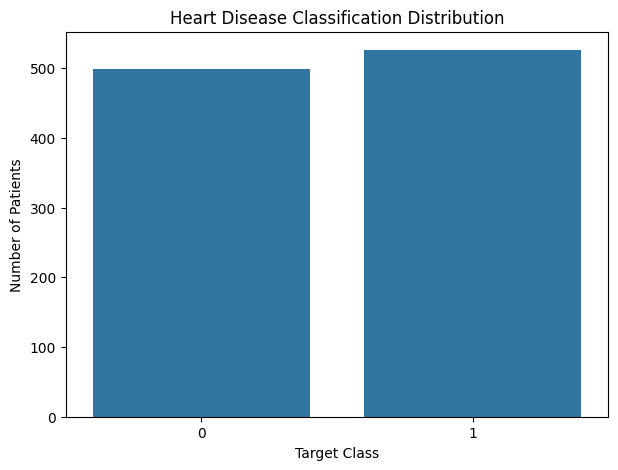

In [8]:

import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(7, 5))

sns.countplot(data=df, x='target')

plt.title("Heart Disease Classification Distribution")
plt.xlabel("Target Class")
plt.ylabel("Number of Patients")

plt.show()


In [9]:

# STEP 4: DATA CLEANING

print("Original Dataset Shape:", df.shape)

# Remove duplicate records
df = df.drop_duplicates().reset_index(drop=True)

print("Dataset Shape After Cleaning:", df.shape)

# Verify duplicates are removed
print("Remaining Duplicates:", df.duplicated().sum())

# Check missing values
print("\nMissing Values:")
print(df.isnull().sum())

# Check target class distribution
print("\nTarget Distribution:")
print(df['target'].value_counts())


Original Dataset Shape: (1025, 14)
Dataset Shape After Cleaning: (302, 14)
Remaining Duplicates: 0

Missing Values:
age         0
sex         0
cp          0
trestbps    0
chol        0
fbs         0
restecg     0
thalach     0
exang       0
oldpeak     0
slope       0
ca          0
thal        0
target      0
dtype: int64

Target Distribution:
target
1    164
0    138
Name: count, dtype: int64


In [10]:

from sklearn.model_selection import train_test_split

# Separate input features and target label
X = df.drop('target', axis=1)
y = df['target']

# Split data: 80% training, 20% testing
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training Samples:", X_train.shape[0])
print("Testing Samples:", X_test.shape[0])

print("\nTraining Class Distribution:")
print(y_train.value_counts())

print("\nTesting Class Distribution:")
print(y_test.value_counts())


Training Samples: 241
Testing Samples: 61

Training Class Distribution:
target
1    131
0    110
Name: count, dtype: int64

Testing Class Distribution:
target
1    33
0    28
Name: count, dtype: int64


In [11]:

# STEP 6: LOGISTIC REGRESSION MODEL

from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score

# Create a machine learning pipeline
model = make_pipeline(
    StandardScaler(),
    LogisticRegression(max_iter=2000, random_state=42)
)

# Train the model
model.fit(X_train, y_train)

# Make predictions on test data
y_pred = model.predict(X_test)

# Calculate accuracy
accuracy = accuracy_score(y_test, y_pred)

print("Logistic Regression Model Trained!")
print(f"Model Accuracy: {accuracy * 100:.2f}%")


Logistic Regression Model Trained!
Model Accuracy: 80.33%


===== CLASSIFICATION REPORT =====
                  precision    recall  f1-score   support

No Heart Disease       0.81      0.75      0.78        28
   Heart Disease       0.80      0.85      0.82        33

        accuracy                           0.80        61
       macro avg       0.80      0.80      0.80        61
    weighted avg       0.80      0.80      0.80        61

===== CONFUSION MATRIX =====
[[21  7]
 [ 5 28]]


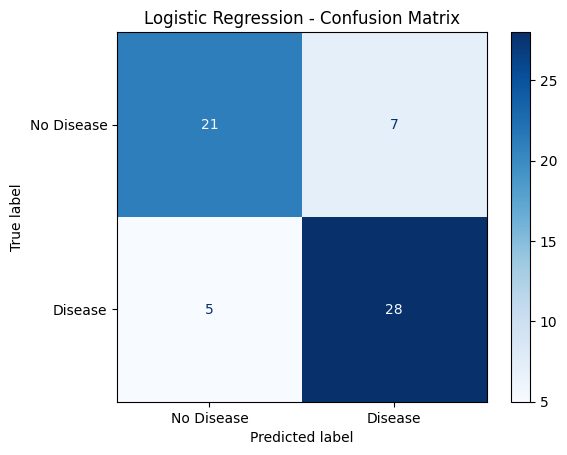

In [12]:

# STEP 7: MODEL EVALUATION

from sklearn.metrics import (
    confusion_matrix,
    classification_report,
    ConfusionMatrixDisplay
)
import matplotlib.pyplot as plt

# Generate classification report
print("===== CLASSIFICATION REPORT =====")
print(classification_report(
    y_test, y_pred,
    target_names=["No Heart Disease", "Heart Disease"]
))

# Generate confusion matrix
cm = confusion_matrix(y_test, y_pred)

print("===== CONFUSION MATRIX =====")
print(cm)

# Visualize the confusion matrix
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["No Disease", "Disease"]
)

disp.plot(cmap="Blues", values_format="d")
plt.title("Logistic Regression - Confusion Matrix")
plt.show()


===== MODEL COMPARISON =====


,Model,Accuracy,Precision,Recall,F1 Score
0,Logistic Regression,0.803,0.800,0.848,0.824
1,Decision Tree,0.721,0.750,0.727,0.738
2,Random Forest,0.770,0.788,0.788,0.788


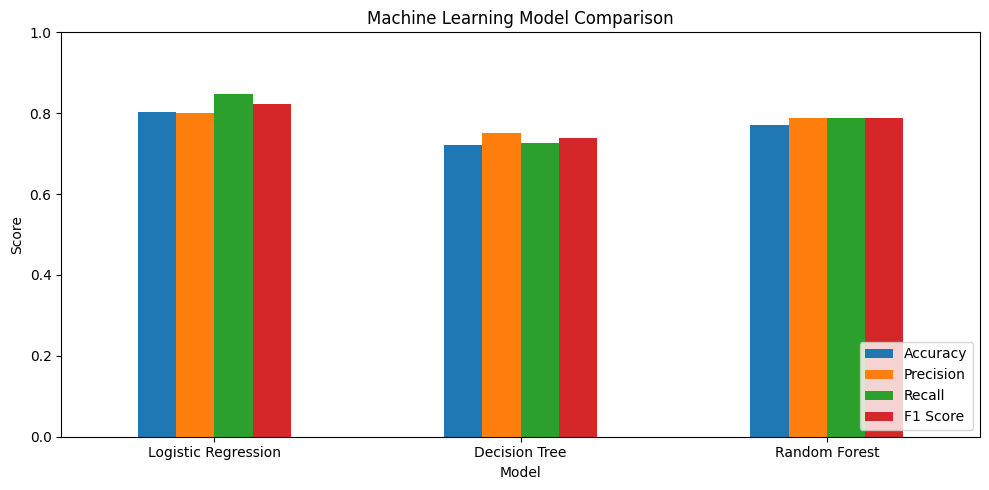

In [13]:

# STEP 8: MODEL COMPARISON

from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, precision_score,
    recall_score, f1_score
)
import pandas as pd
import matplotlib.pyplot as plt

# Define models
models = {
    "Logistic Regression": model,
    "Decision Tree": DecisionTreeClassifier(
        max_depth=4, random_state=42
    ),
    "Random Forest": RandomForestClassifier(
        n_estimators=100,
        max_depth=5,
        random_state=42
    )
}

results = []

# Train and evaluate each model
for name, clf in models.items():
    clf.fit(X_train, y_train)
    predictions = clf.predict(X_test)

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision": precision_score(y_test, predictions),
        "Recall": recall_score(y_test, predictions),
        "F1 Score": f1_score(y_test, predictions)
    })

# Display results
results_df = pd.DataFrame(results)

print("===== MODEL COMPARISON =====")
display(results_df.round(3))

# Visual comparison
results_df.set_index("Model")[
    ["Accuracy", "Precision", "Recall", "F1 Score"]
].plot(kind="bar", figsize=(10, 5))

plt.title("Machine Learning Model Comparison")
plt.ylabel("Score")
plt.ylim(0, 1)
plt.xticks(rotation=0)
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()


In [14]:

# STEP 9: CROSS-VALIDATION

from sklearn.model_selection import (
    StratifiedKFold, cross_validate
)
import pandas as pd

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

cv_results = []

for name, clf in models.items():

    scores = cross_validate(
        clf,
        X_train,
        y_train,
        cv=cv,
        scoring={
            "accuracy": "accuracy",
            "precision": "precision",
            "recall": "recall",
            "f1": "f1"
        }
    )

    cv_results.append({
        "Model": name,
        "Mean Accuracy": scores["test_accuracy"].mean(),
        "Mean Precision": scores["test_precision"].mean(),
        "Mean Recall": scores["test_recall"].mean(),
        "Mean F1": scores["test_f1"].mean()
    })

cv_df = pd.DataFrame(cv_results)

print("===== 5-FOLD CROSS-VALIDATION RESULTS =====")
display(cv_df.round(3))

print("\nBest Model by Cross-Validation F1:")
print(cv_df.loc[cv_df["Mean F1"].idxmax(), "Model"])


===== 5-FOLD CROSS-VALIDATION RESULTS =====


,Model,Mean Accuracy,Mean Precision,Mean Recall,Mean F1
0,Logistic Regression,0.838,0.828,0.901,0.860
1,Decision Tree,0.743,0.773,0.771,0.759
2,Random Forest,0.859,0.848,0.908,0.875



Best Model by Cross-Validation F1:
Random Forest


===== EXTENDED MODEL COMPARISON =====


,Model,Mean Accuracy,Mean Precision,Mean Recall,Mean F1,F1 Std
0,Random Forest (100 Trees),0.859,0.848,0.908,0.875,0.053
1,Random Forest (200 Trees),0.855,0.847,0.901,0.871,0.046
2,Random Forest (50 Trees),0.842,0.831,0.901,0.862,0.062
3,Extra Trees (200 Trees),0.842,0.853,0.877,0.860,0.042
4,Logistic Regression,0.838,0.828,0.901,0.860,0.068
5,Extra Trees (100 Trees),0.834,0.848,0.862,0.850,0.036
6,Gradient Boosting (100),0.826,0.816,0.885,0.847,0.026
7,Gradient Boosting (50),0.817,0.818,0.870,0.839,0.023
8,Decision Tree (Depth 10),0.780,0.781,0.832,0.804,0.027
9,Decision Tree (Depth 7),0.759,0.774,0.794,0.781,0.022


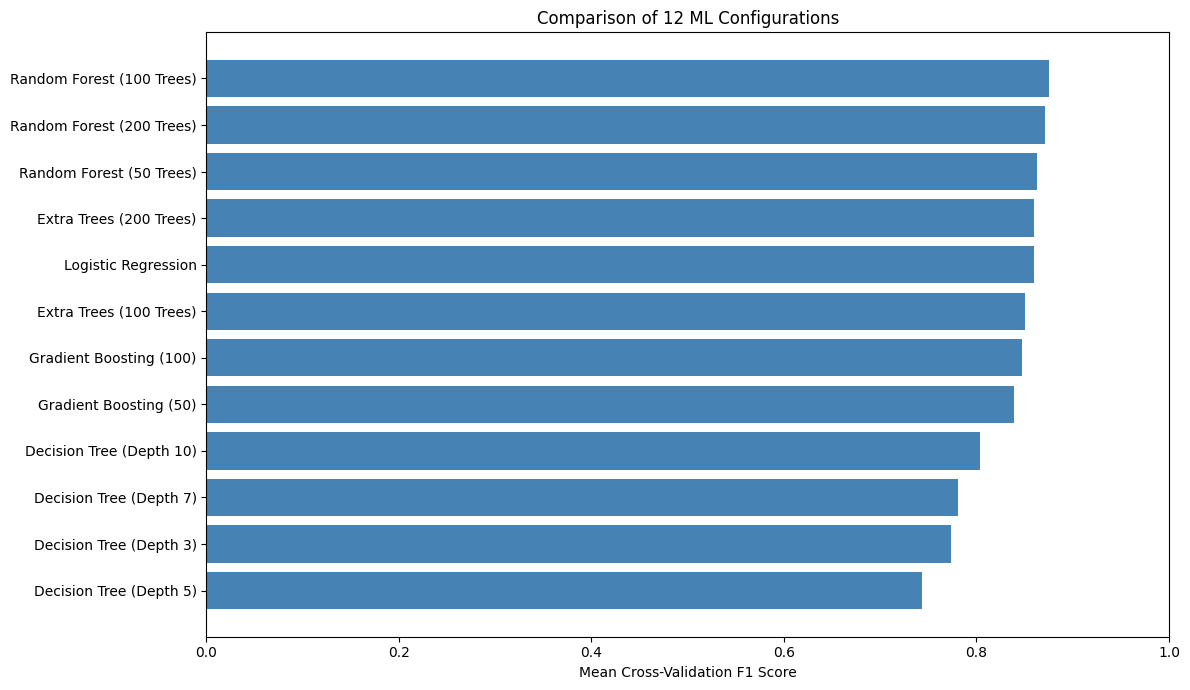


===== SELECTED MODEL =====
Best Model: Random Forest (100 Trees)
Cross-Validation F1: 0.8752

===== SELECTED MODEL TEST RESULTS =====
Accuracy:  0.7705
Precision: 0.7879
Recall:    0.7879
F1 Score:  0.7879

Extended comparison complete!


In [15]:

# ===================================================
# STEP 9A: EXTENDED MACHINE LEARNING EXPERIMENTS
# Decision Trees, Random Forest and Ensemble Methods
# ===================================================

import pandas as pd
import matplotlib.pyplot as plt

from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import (
    RandomForestClassifier,
    ExtraTreesClassifier,
    GradientBoostingClassifier
)
from sklearn.model_selection import (
    StratifiedKFold, cross_validate
)
from sklearn.metrics import (
    accuracy_score, precision_score,
    recall_score, f1_score,
    classification_report, confusion_matrix,
    ConfusionMatrixDisplay
)

# 1. DEFINE DIFFERENT MODEL CONFIGURATIONS

extended_models = {
    "Logistic Regression": models["Logistic Regression"],

    "Decision Tree (Depth 3)": DecisionTreeClassifier(
        max_depth=3, random_state=42
    ),

    "Decision Tree (Depth 5)": DecisionTreeClassifier(
        max_depth=5, random_state=42
    ),

    "Decision Tree (Depth 7)": DecisionTreeClassifier(
        max_depth=7, random_state=42
    ),

    "Decision Tree (Depth 10)": DecisionTreeClassifier(
        max_depth=10, random_state=42
    ),

    "Random Forest (50 Trees)": RandomForestClassifier(
        n_estimators=50, max_depth=5, random_state=42
    ),

    "Random Forest (100 Trees)": RandomForestClassifier(
        n_estimators=100, max_depth=5, random_state=42
    ),

    "Random Forest (200 Trees)": RandomForestClassifier(
        n_estimators=200, max_depth=5, random_state=42
    ),

    "Extra Trees (100 Trees)": ExtraTreesClassifier(
        n_estimators=100, random_state=42
    ),

    "Extra Trees (200 Trees)": ExtraTreesClassifier(
        n_estimators=200, random_state=42
    ),

    "Gradient Boosting (50)": GradientBoostingClassifier(
        n_estimators=50, random_state=42
    ),

    "Gradient Boosting (100)": GradientBoostingClassifier(
        n_estimators=100, random_state=42
    )
}

# 2. CREATE STRATIFIED CROSS-VALIDATION

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

results_extended = []

# 3. EVALUATE EACH MODEL ON TRAINING DATA

for name, clf in extended_models.items():

    scores = cross_validate(
        clf,
        X_train,
        y_train,
        cv=cv,
        scoring={
            "accuracy": "accuracy",
            "precision": "precision",
            "recall": "recall",
            "f1": "f1"
        }
    )

    results_extended.append({
        "Model": name,
        "Mean Accuracy": scores["test_accuracy"].mean(),
        "Mean Precision": scores["test_precision"].mean(),
        "Mean Recall": scores["test_recall"].mean(),
        "Mean F1": scores["test_f1"].mean(),
        "F1 Std": scores["test_f1"].std()
    })

# 4. RANK THE MODELS BY F1-SCORE

extended_df = pd.DataFrame(results_extended)

extended_df = extended_df.sort_values(
    by="Mean F1", ascending=False
).reset_index(drop=True)

print("===== EXTENDED MODEL COMPARISON =====")
display(extended_df.round(3))

# 5. VISUALIZE F1-SCORES

plt.figure(figsize=(12, 7))

plt.barh(
    extended_df["Model"],
    extended_df["Mean F1"],
    color="steelblue"
)

plt.xlabel("Mean Cross-Validation F1 Score")
plt.title("Comparison of 12 ML Configurations")
plt.xlim(0, 1)
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

# 6. SELECT BEST MODEL USING CV F1

best_model_name = extended_df.iloc[0]["Model"]

best_model = extended_models[best_model_name]

print("\n===== SELECTED MODEL =====")
print("Best Model:", best_model_name)
print(
    "Cross-Validation F1:",
    round(extended_df.iloc[0]["Mean F1"], 4)
)

# 7. TRAIN SELECTED MODEL

best_model.fit(X_train, y_train)

# 8. EVALUATE ON HELD-OUT TEST SET

final_predictions = best_model.predict(X_test)

final_accuracy = accuracy_score(
    y_test, final_predictions
)

final_precision = precision_score(
    y_test, final_predictions,
    zero_division=0
)

final_recall = recall_score(
    y_test, final_predictions,
    zero_division=0
)

final_f1 = f1_score(
    y_test, final_predictions,
    zero_division=0
)

print("\n===== SELECTED MODEL TEST RESULTS =====")
print(f"Accuracy:  {final_accuracy:.4f}")
print(f"Precision: {final_precision:.4f}")
print(f"Recall:    {final_recall:.4f}")
print(f"F1 Score:  {final_f1:.4f}")

# 9. UPDATE VARIABLES FOR EXISTING NOTEBOOK CELLS

models = extended_models

cv_df = extended_df.copy()

print("\nExtended comparison complete!")


In [16]:

# STEP 10: HEART DISEASE PREDICTION SYSTEM

import pandas as pd
from IPython.display import display
import ipywidgets as widgets

# Select the best model based on cross-validation
best_model_name = cv_df.loc[
    cv_df["Mean F1"].idxmax(), "Model"
]

best_model = models[best_model_name]

# Train selected model on the training dataset
best_model.fit(X_train, y_train)

print("Selected Model:", best_model_name)

# Create interactive input fields
inputs = {}

for column in X_train.columns:
    inputs[column] = widgets.FloatText(
        value=float(X_train[column].median()),
        description=column,
        style={'description_width': '100px'}
    )

predict_button = widgets.Button(
    description="Predict Heart Disease",
    button_style="primary"
)

output = widgets.Output()

def predict_heart_disease(button):
    with output:
        output.clear_output()

        patient = pd.DataFrame(
            [{col: widget.value
              for col, widget in inputs.items()}]
        )

        prediction = best_model.predict(patient)[0]
        probability = best_model.predict_proba(patient)[0]

        print("===== PREDICTION RESULT =====")

        if prediction == 1:
            print("Classification: HEART DISEASE")
        else:
            print("Classification: NO HEART DISEASE")

        class_index = list(best_model.classes_).index(1)

        print(
            f"Estimated Model Probability "
            f"(Class 1): {probability[class_index]*100:.2f}%"
        )

        print("\nEducational demonstration only.")
        print("Not a medical diagnosis.")

predict_button.on_click(predict_heart_disease)

display(widgets.VBox(list(inputs.values()) + [
    predict_button,
    output
]))


Selected Model: Random Forest (100 Trees)


In [20]:
# STEP 11: SAVE TRAINED MODEL

import joblib
import os

# Define folder and full file path
folder_path = r"C:\Users\lenovo\OneDrive\Desktop\machine_learning_mini_project\models"
os.makedirs(folder_path, exist_ok=True)  # Creates the folder if it doesn't exist

model_path = os.path.join(folder_path, "model.pkl")

# Save the selected trained model
joblib.dump(best_model, model_path)

print("Model saved successfully!")
print("Selected Algorithm:", best_model_name)
print("Saved Location:", model_path)
print("File Size:", os.path.getsize(model_path), "bytes")


Model saved successfully!
Selected Algorithm: Random Forest (100 Trees)
Saved Location: C:\Users\lenovo\OneDrive\Desktop\machine_learning_mini_project\models\model.pkl
File Size: 377113 bytes


===== FEATURE IMPORTANCE =====


,Feature,Importance
12,thal,0.0664
11,ca,0.0554
9,oldpeak,0.0315
1,sex,0.0127
10,slope,0.0105
8,exang,0.0067
0,age,0.0045
5,fbs,0.0012
6,restecg,0.0000
7,thalach,-0.0084


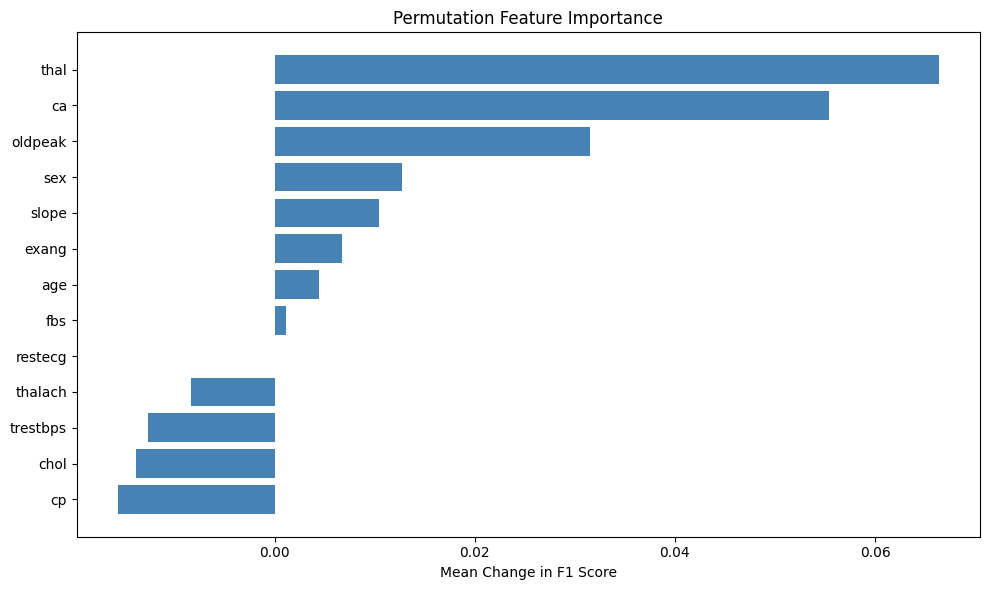

In [22]:

# STEP 12: UNIVERSAL FEATURE IMPORTANCE

from sklearn.inspection import permutation_importance
import pandas as pd
import matplotlib.pyplot as plt

importance_result = permutation_importance(
    best_model,
    X_test,
    y_test,
    scoring="f1",
    n_repeats=10,
    random_state=42
)

feature_df = pd.DataFrame({
    "Feature": X_test.columns,
    "Importance": importance_result.importances_mean
}).sort_values("Importance", ascending=False)

print("===== FEATURE IMPORTANCE =====")
display(feature_df.round(4))

plt.figure(figsize=(10, 6))

plt.barh(
    feature_df["Feature"],
    feature_df["Importance"],
    color="steelblue"
)

plt.xlabel("Mean Change in F1 Score")
plt.title("Permutation Feature Importance")
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()


HEART DISEASE CLASSIFICATION - FINAL RESULTS

Selected Algorithm: Random Forest (100 Trees)
Training Samples: 241
Testing Samples: 61

PERFORMANCE METRICS
Accuracy:  77.05%
Precision: 78.79%
Recall:    78.79%
F1 Score:  78.79%

CLASSIFICATION REPORT
               precision    recall  f1-score   support

   No Disease       0.75      0.75      0.75        28
Heart Disease       0.79      0.79      0.79        33

     accuracy                           0.77        61
    macro avg       0.77      0.77      0.77        61
 weighted avg       0.77      0.77      0.77        61



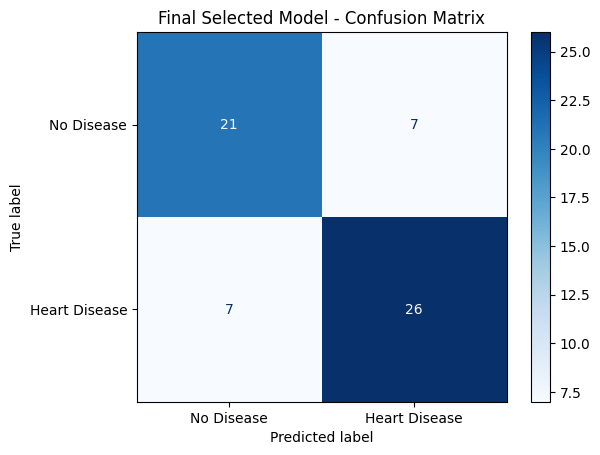


SAMPLE PREDICTION


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal
24,61,0,0,145,307,0,0,146,1,1.0,1,0,3


Predicted Class: 0
Actual Class: 0
Output: No Heart Disease Class

Educational ML demonstration only.
Not a clinical diagnostic system.


In [23]:

# ==========================================
# STEP 13: FINAL PROJECT RESULTS
# ==========================================

from sklearn.metrics import (
    classification_report,
    ConfusionMatrixDisplay
)
import matplotlib.pyplot as plt
import pandas as pd

# Selected model evaluation
final_predictions = best_model.predict(X_test)

print("=" * 50)
print("HEART DISEASE CLASSIFICATION - FINAL RESULTS")
print("=" * 50)

print("\nSelected Algorithm:", best_model_name)
print("Training Samples:", len(X_train))
print("Testing Samples:", len(X_test))

print("\nPERFORMANCE METRICS")
print(f"Accuracy:  {final_accuracy * 100:.2f}%")
print(f"Precision: {final_precision * 100:.2f}%")
print(f"Recall:    {final_recall * 100:.2f}%")
print(f"F1 Score:  {final_f1 * 100:.2f}%")

print("\nCLASSIFICATION REPORT")
print(classification_report(
    y_test,
    final_predictions,
    target_names=["No Disease", "Heart Disease"]
))

# Final confusion matrix
ConfusionMatrixDisplay.from_predictions(
    y_test,
    final_predictions,
    display_labels=["No Disease", "Heart Disease"],
    cmap="Blues"
)

plt.title("Final Selected Model - Confusion Matrix")
plt.show()

# Demonstrate prediction on a test sample
sample = X_test.iloc[[0]]
sample_prediction = best_model.predict(sample)[0]

print("\nSAMPLE PREDICTION")
display(sample)

print("Predicted Class:", int(sample_prediction))
print("Actual Class:", int(y_test.iloc[0]))

if sample_prediction == 1:
    print("Output: Heart Disease Class")
else:
    print("Output: No Heart Disease Class")

print("\nEducational ML demonstration only.")
print("Not a clinical diagnostic system.")


# HEART DISEASE CLASSIFICATION USING MACHINE LEARNING

## 1. Project Overview

This project focuses on the development and comparative evaluation of machine learning classification algorithms for predicting heart disease labels from patient-related medical measurements.

The primary objective is to study how different supervised learning algorithms perform on a structured medical dataset and investigate the effects of model complexity, hyperparameter selection, and ensemble learning techniques.

The project implements multiple machine learning models, evaluates their performance using statistical metrics, and provides an interactive classification system for demonstration purposes.

---

## 2. Project Objectives

The major objectives of this project are:

1. To explore and preprocess a heart disease dataset.
2. To identify missing values, duplicate records, and important features.
3. To implement and compare different supervised machine learning algorithms.
4. To investigate the influence of decision tree depth and ensemble size.
5. To evaluate models using accuracy, precision, recall, F1-score, and confusion matrices.
6. To perform five-fold stratified cross-validation for model comparison.
7. To identify influential features through feature importance analysis.
8. To develop an interactive prediction system using a selected trained model.

---

## 3. Dataset Description

The Heart Disease Dataset was obtained from Kaggle and contains medical attributes that may be associated with heart disease classification.

The dataset includes 13 input features, such as:

- Age and sex
- Chest pain type
- Resting blood pressure
- Serum cholesterol
- Fasting blood sugar indicator
- Resting electrocardiographic results
- Maximum heart rate achieved
- Exercise-induced angina
- ST depression and ST segment slope
- Number of major vessels
- Thalassemia-related test category

The target variable represents the binary heart disease classification label.

During preprocessing, 723 duplicate rows were identified and removed. The resulting dataset contained 302 unique records.

The cleaned dataset was divided into 241 training samples and 61 testing samples using an 80:20 stratified train-test split.

---

## 4. Machine Learning Algorithms Implemented

The project evaluates the following machine learning approaches:

### Logistic Regression

A supervised classification algorithm that estimates the probability of a binary outcome using a logistic function. It serves as the baseline model for comparing more complex algorithms.

### Decision Tree Classifier

A tree-based classification algorithm that recursively divides data using decision rules.

Different maximum depths of 3, 5, 7, and 10 were investigated to examine how tree complexity affects classification performance and the risk of overfitting.

### Random Forest Classifier

An ensemble learning algorithm that combines predictions from multiple decision trees to produce a final classification.

Random Forest configurations containing 50, 100, and 200 trees were investigated to study how ensemble size influences predictive performance.

### Extra Trees Classifier

An ensemble algorithm that introduces additional randomization into decision tree construction. Configurations containing 100 and 200 trees were evaluated.

### Gradient Boosting Classifier

An ensemble learning technique that trains multiple weak learners sequentially, with later learners focusing on improving the model's predictions.

Configurations containing 50 and 100 boosting estimators were investigated.

In total, 12 machine learning configurations were included in the extended comparison.

---

## 5. Model Evaluation Methodology

To assess classification performance, the following evaluation metrics were used:

**Accuracy:** Measures the proportion of correctly classified samples.

**Precision:** Measures the proportion of predicted positive classifications that are correct.

**Recall:** Measures the proportion of actual positive cases correctly identified by the model.

**F1-score:** Represents the harmonic mean of precision and recall, balancing the two metrics.

**Confusion Matrix:** Displays true positives, true negatives, false positives, and false negatives.

**Five-Fold Stratified Cross-Validation:** Evaluates the models across five different training-validation partitions while preserving approximately the same class proportions.

Mean F1-score was used as the primary selection criterion for the extended model comparison.

---

## 6. Experimental Results and Observations

The initial three-algorithm comparison produced the following results:

| Algorithm | Test Accuracy | Cross-Validation Accuracy | Cross-Validation F1 |
|---|---:|---:|---:|
| Logistic Regression | 80.33% | 83.8% | 86.0% |
| Decision Tree | 72.1% | 74.3% | 75.9% |
| Random Forest | 77.0% | 85.9% | 87.5% |

In the initial experiment, Logistic Regression achieved the highest accuracy on the held-out test set.

Random Forest achieved the highest mean cross-validation accuracy and F1-score among the initial three models.

The extended experiment subsequently compared 12 configurations, including variations in tree depth, ensemble size, and learning algorithms.

The complete extended cross-validation rankings and final selected-model performance are presented in the output of Step 9A and Step 13 of this notebook.

These experiments demonstrate that increasing model complexity does not necessarily guarantee better generalization performance.

---

## 7. Feature Importance Analysis

Feature importance analysis was conducted to investigate which input attributes contributed most to the selected model's predictive performance.

The original Random Forest analysis identified chest pain type, maximum heart rate achieved, number of major vessels, the thalassemia-related category, and exercise-induced angina among the most influential features.

An additional permutation importance analysis was included to support interpretation of different model types.

Feature importance scores describe model behavior and should not be interpreted as proof of medical causation.

---

## 8. Interactive Prediction System

An interactive prediction system was developed using Python and IPython widgets within Kaggle.

The system allows users to enter values for the 13 input features and submit them to a trained classification model.

The output includes:

- Predicted classification label
- Model-estimated probability for the positive class
- Identification of the selected model
- A disclaimer explaining the educational nature of the system

The trained model was also saved using Joblib for future reuse.

---

## 9. Project Limitations

Although the project successfully demonstrates machine learning classification techniques, several limitations must be acknowledged.

1. The cleaned dataset contains only 302 records, limiting the statistical reliability of performance estimates.
2. Results may vary with different training and testing partitions.
3. Cross-validation performance may differ from held-out test performance because the models are evaluated on different subsets of data.
4. Hyperparameter configurations were manually specified rather than optimized through an exhaustive search.
5. Some input features are categorical and require correct dataset-specific encoding.
6. The dataset does not establish whether the trained models generalize to different populations or clinical settings.
7. The predicted probabilities have not been clinically calibrated or validated.
8. Model selection and exploratory comparisons involving the test set can introduce evaluation bias.

Consequently